In [1]:

%pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [3]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [ ]:
from pathlib import Path

data_path = Path("Online Retail.xlsx")

if not data_path.exists():
    try:
        import urllib.request
        url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
        zip_path = Path("online-retail.zip")
        urllib.request.urlretrieve(url, zip_path)

        import zipfile
        with zipfile.ZipFile(zip_path, "r") as zf:
            excel_files = [name for name in zf.namelist() if name.lower().endswith(".xlsx")]
            if not excel_files:
                raise FileNotFoundError("No Excel workbook was found inside the downloaded ZIP.")
            selected = excel_files[0]
            data_path.write_bytes(zf.read(selected))
        print("Dataset downloaded.")
    except Exception as e:
        print("Automatic download failed:", e)
        try:
            from google.colab import files
            uploaded = files.upload()
            data_path = Path(next(iter(uploaded)))
        except Exception:
            raise RuntimeError("Please place 'Online Retail.xlsx' in the notebook folder and run this cell again.")

df_raw = pd.read_excel(data_path)
print("Raw shape:", df_raw.shape)
display(df_raw.head())

## 3. Initial data inspection

In [6]:
import pandas as pd
from pathlib import Path

data_path = Path("Online Retail.xlsx")


if not data_path.exists():
    try:
        import urllib.request
        url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
        zip_path = Path("online-retail.zip")
        print("Downloading dataset...")
        urllib.request.urlretrieve(url, zip_path)

        import zipfile
        with zipfile.ZipFile(zip_path, "r") as zf:
            excel_files = [name for name in zf.namelist() if name.lower().endswith(".xlsx")]
            if not excel_files:
                raise FileNotFoundError("No Excel workbook was found inside the downloaded ZIP.")
            selected = excel_files[0]
            data_path.write_bytes(zf.read(selected))
        print("Dataset downloaded.")
    except Exception as e:
        print("Download failed, please upload 'Online Retail.xlsx' manually:", e)

df_raw = pd.read_excel(data_path)
print("Raw shape:", df_raw.shape)


Dataset downloaded.
Raw shape: (541909, 8)


In [7]:
print("Rows and columns:", df_raw.shape)
display(df_raw.info())
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
display(df_raw.describe(include="all").T)

Rows and columns: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


None

,missing_values
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,"541,909.00","25,900.00","573,585.00","1,114.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,"-80,995.00",1.00,3.00,10.00,"80,995.00",218.08
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,"-11,062.06",1.25,2.08,4.13,"38,970.00",96.76
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00","1,713.60"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df = df_raw.copy()

# Map original columns directly to standardized names to avoid regex/casing mismatch
column_mapping = {
    "InvoiceNo": "invoice_no",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "UnitPrice": "unit_price",
    "CustomerID": "customer_id",
    "Country": "country"
}
df = df.rename(columns=column_mapping)

# Expected UCI columns after standardisation:
# invoice_no, stock_code, description, quantity, invoice_date,
# unit_price, customer_id, country

required_cols = ["invoice_no", "stock_code", "quantity", "invoice_date", "unit_price"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")

df["invoice_date"] = pd.to_datetime(df["invoice_date"], errors="coerce")
for col in ["quantity", "unit_price", "customer_id"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Cancellation rows:", df["invoice_no"].astype(str).str.startswith("C", na=False).sum())
print("Exact duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna(subset=["invoice_no", "stock_code", "quantity", "invoice_date", "unit_price"])

# Main positive-sales dataset. Returns/cancellations are not included in this simplified view.
sales = df[
    (~df["invoice_no"].astype(str).str.startswith("C")) &
    (df["quantity"] > 0) &
    (df["unit_price"] > 0)
].copy()

sales["sales_value"] = sales["quantity"] * sales["unit_price"]
sales["customer_id"] = sales["customer_id"].astype("Int64")

print("Clean sales shape:", sales.shape)
display(sales.head())
print("Missing values after essential-field cleaning:")
display(sales.isna().sum().to_frame("missing_values"))

Cancellation rows: 9288
Exact duplicate rows: 5268
Clean sales shape: (524878, 9)


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,sales_value
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Missing values after essential-field cleaning:


,missing_values
invoice_no,0
stock_code,0
description,0
quantity,0
invoice_date,0
unit_price,0
customer_id,132186
country,0
sales_value,0


In [10]:
quality_summary = pd.DataFrame({
    "check": [
        "Rows in raw data",
        "Exact duplicates in raw data",
        "Rows with missing customer ID (clean sales)",
        "Rows with invalid/missing invoice date after conversion",
        "Rows with non-positive quantity in clean sales",
        "Rows with non-positive unit price in clean sales"
    ],
    "count": [
        len(df_raw),
        df_raw.duplicated().sum(),
        sales["customer_id"].isna().sum(),
        df["invoice_date"].isna().sum(),
        (sales["quantity"] <= 0).sum(),
        (sales["unit_price"] <= 0).sum()
    ]
})
display(quality_summary)

,check,count
0,Rows in raw data,541909
1,Exact duplicates in raw data,5268
2,Rows with missing customer ID (clean sales),132186
3,Rows with invalid/missing invoice date after c...,0
4,Rows with non-positive quantity in clean sales,0
5,Rows with non-positive unit price in clean sales,0


In [11]:
# Overall summary
summary = {
    "transaction_lines": len(sales),
    "unique_invoices": sales["invoice_no"].nunique(),
    "unique_products": sales["stock_code"].nunique(),
    "identified_customers": sales["customer_id"].nunique(),
    "total_units": sales["quantity"].sum(),
    "total_sales_value": sales["sales_value"].sum(),
    "average_line_value": sales["sales_value"].mean(),
    "median_line_value": sales["sales_value"].median()
}
display(pd.Series(summary, name="value").to_frame())

,value
transaction_lines,"524,878.00"
unique_invoices,"19,960.00"
unique_products,"3,922.00"
identified_customers,"4,338.00"
total_units,"5,572,420.00"
total_sales_value,"10,642,110.80"
average_line_value,20.28
median_line_value,9.92


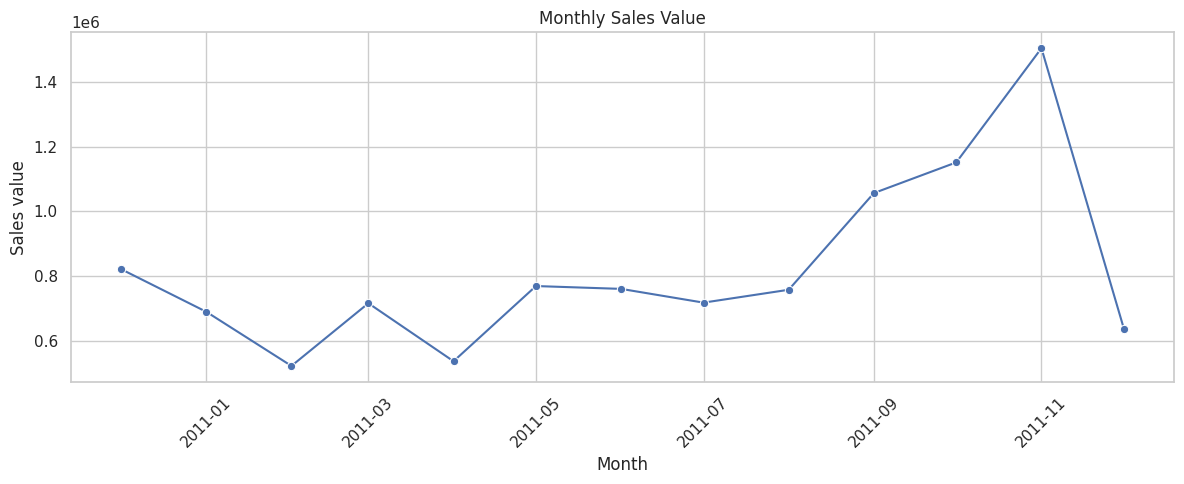

,invoice_date,orders,sales_value,units
0,2010-12-01,1559,"821,452.73",358019
1,2011-01-01,1086,"689,811.61",387099
2,2011-02-01,1100,"522,545.56",282934
3,2011-03-01,1454,"716,215.26",376599
4,2011-04-01,1246,"536,968.49",307953


In [12]:
# Monthly sales trend
monthly = (sales.set_index("invoice_date")
           .resample("MS")
           .agg(orders=("invoice_no", "nunique"),
                sales_value=("sales_value", "sum"),
                units=("quantity", "sum"))
           .reset_index())

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x="invoice_date", y="sales_value", marker="o", ax=ax)
ax.set(title="Monthly Sales Value", xlabel="Month", ylabel="Sales value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
display(monthly.head())

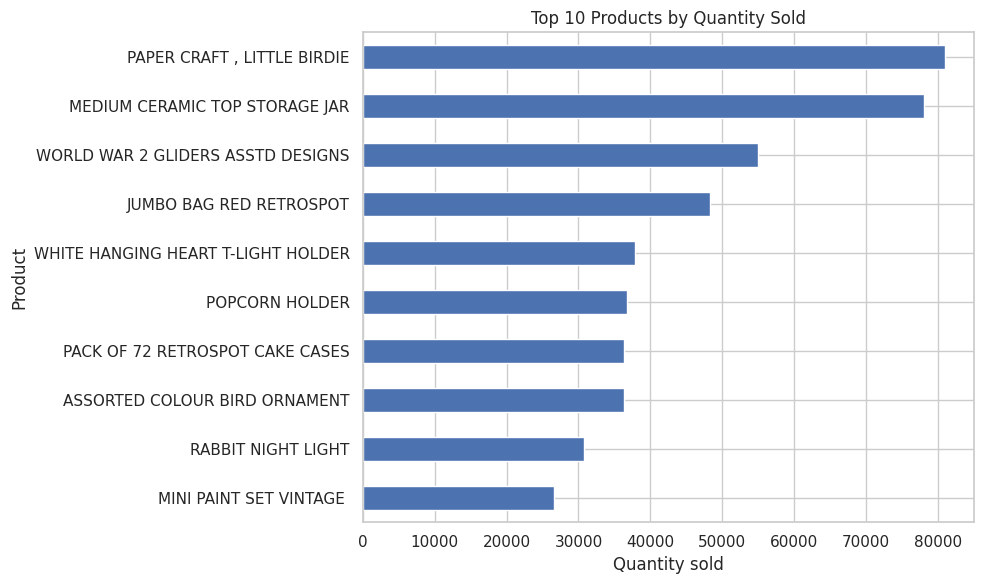

,quantity_sold
description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
JUMBO BAG RED RETROSPOT,48371
WHITE HANGING HEART T-LIGHT HOLDER,37872
POPCORN HOLDER,36749
PACK OF 72 RETROSPOT CAKE CASES,36396
ASSORTED COLOUR BIRD ORNAMENT,36362
RABBIT NIGHT LIGHT,30739


In [13]:
# Top products by quantity sold
product_col = "description" if "description" in sales.columns else "stock_code"
top_products = (sales.groupby(product_col, dropna=False)["quantity"]
                .sum().sort_values(ascending=False).head(10).sort_values())

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()
display(top_products.sort_values(ascending=False).to_frame("quantity_sold"))

In [14]:
customer_sales = sales.dropna(subset=["customer_id"]).copy()
snapshot_date = customer_sales["invoice_date"].max() + pd.Timedelta(days=1)

rfm = (customer_sales.groupby("customer_id")
       .agg(
           recency=("invoice_date", lambda x: (snapshot_date - x.max()).days),
           frequency=("invoice_no", "nunique"),
           monetary=("sales_value", "sum")
       )
       .reset_index())

display(rfm.head())
display(rfm[["recency", "frequency", "monetary"]].describe())

,customer_id,recency,frequency,monetary
0,12346,326,1,"77,183.60"
1,12347,2,7,"4,310.00"
2,12348,75,4,"1,797.24"
3,12349,19,1,"1,757.55"
4,12350,310,1,334.40


,recency,frequency,monetary
count,"4,338.00","4,338.00","4,338.00"
mean,92.54,4.27,"2,048.69"
std,100.01,7.70,"8,985.23"
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,"1,660.60"
max,374.00,209.00,"280,206.02"


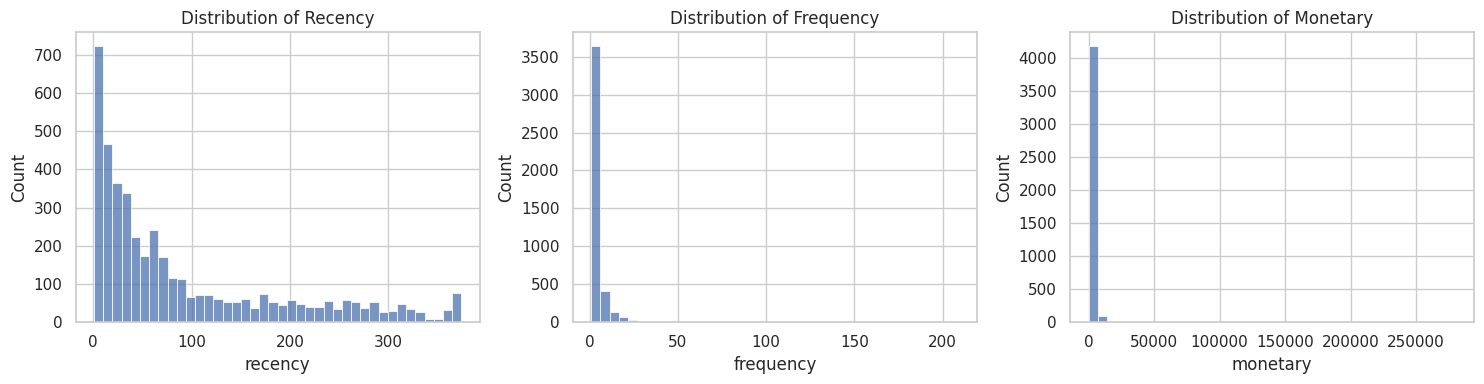

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["recency", "frequency", "monetary"]):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"Distribution of {col.title()}")
plt.tight_layout()
plt.show()

In [16]:
orders = (customer_sales.groupby(["customer_id", "invoice_no"], as_index=False)
          .agg(order_date=("invoice_date", "min"),
               order_value=("sales_value", "sum")))

orders = orders.sort_values(["customer_id", "order_date"])
first_orders = orders.groupby("customer_id", as_index=False).first()
first_orders = first_orders.rename(columns={
    "order_date": "prediction_date",
    "order_value": "first_order_value"
})

def has_repeat_within_60_days(customer_id, prediction_date):
    customer_dates = orders.loc[orders["customer_id"] == customer_id, "order_date"]
    return int(((customer_dates > prediction_date) &
                (customer_dates <= prediction_date + pd.Timedelta(days=60))).any())

first_orders["repeat_within_60d"] = first_orders.apply(
    lambda row: has_repeat_within_60_days(row["customer_id"], row["prediction_date"]),
    axis=1
)

print("Customers in target table:", len(first_orders))
display(first_orders.head())
display(first_orders["repeat_within_60d"].value_counts(normalize=True).rename("proportion"))

Customers in target table: 4338


,customer_id,invoice_no,prediction_date,first_order_value,repeat_within_60d
0,12346,541431,2011-01-18 10:01:00,"77,183.60",0
1,12347,537626,2010-12-07 14:57:00,711.79,1
2,12348,539318,2010-12-16 19:09:00,892.80,1
3,12349,577609,2011-11-21 09:51:00,"1,757.55",0
4,12350,543037,2011-02-02 16:01:00,334.40,0


,proportion
repeat_within_60d,
0,0.64
1,0.36


In [17]:
rfm_model = rfm.copy()
for col in ["recency", "frequency", "monetary"]:
    rfm_model[col] = np.log1p(rfm_model[col].clip(lower=0))

scaler = StandardScaler()
X_rfm_scaled = scaler.fit_transform(rfm_model[["recency", "frequency", "monetary"]])

# Compare a few cluster counts. Silhouette score is calculated only when valid.
cluster_results = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_rfm_scaled)
    score = silhouette_score(X_rfm_scaled, labels)
    cluster_results.append({"k": k, "silhouette_score": score})

cluster_scores = pd.DataFrame(cluster_results)
display(cluster_scores)

best_k = int(cluster_scores.loc[cluster_scores["silhouette_score"].idxmax(), "k"])
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
rfm["cluster"] = kmeans.fit_predict(X_rfm_scaled)

display(rfm.groupby("cluster")[["recency", "frequency", "monetary"]].mean().round(2))

,k,silhouette_score
0,2,0.43
1,3,0.34
2,4,0.34
3,5,0.32
4,6,0.31


,recency,frequency,monetary
cluster,,,
0,134.09,1.67,495.59
1,25.89,8.44,"4,539.60"


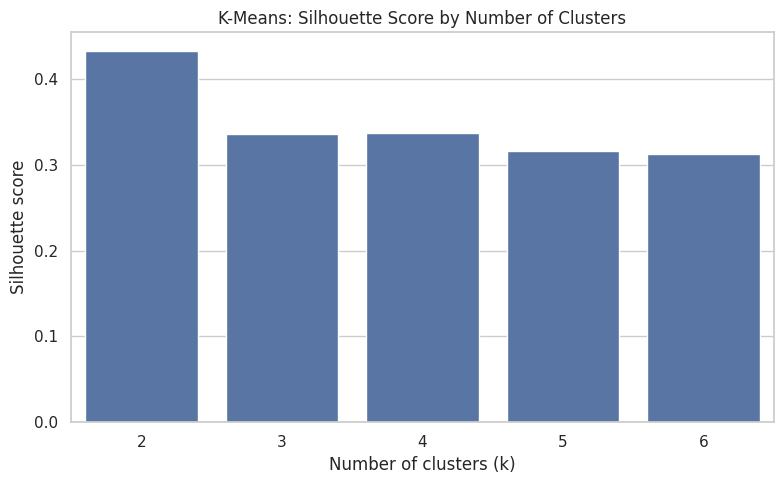

In [18]:
plt.figure(figsize=(8, 5))
sns.barplot(data=cluster_scores, x="k", y="silhouette_score")
plt.title("K-Means: Silhouette Score by Number of Clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.tight_layout()
plt.show()

In [19]:
model_data = first_orders.copy()
model_data["order_month"] = model_data["prediction_date"].dt.month
model_data["order_weekday"] = model_data["prediction_date"].dt.dayofweek
model_data["log_first_order_value"] = np.log1p(model_data["first_order_value"].clip(lower=0))

feature_cols = ["log_first_order_value", "order_month", "order_weekday"]
X = model_data[feature_cols].replace([np.inf, -np.inf], np.nan)
y = model_data["repeat_within_60d"]

valid = X.notna().all(axis=1) & y.notna()
X, y = X.loc[valid], y.loc[valid]

# Chronological split by prediction date
ordered_idx = model_data.loc[valid].sort_values("prediction_date").index
split_at = int(len(ordered_idx) * 0.8)
train_idx, test_idx = ordered_idx[:split_at], ordered_idx[split_at:]

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("Train size:", len(X_train), "Test size:", len(X_test))
print("Train target distribution:")
display(y_train.value_counts(normalize=True).rename("proportion"))

Train size: 3470 Test size: 868
Train target distribution:


,proportion
repeat_within_60d,
0,0.62
1,0.38


In [20]:
if len(X_train) > 0 and y_train.nunique() == 2 and y_test.nunique() == 2:
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)
    baseline_pred = baseline.predict(X_test)

    logistic = LogisticRegression(max_iter=1000, class_weight="balanced")
    logistic.fit(X_train, y_train)
    logistic_pred = logistic.predict(X_test)
    logistic_prob = logistic.predict_proba(X_test)[:, 1]

    forest = RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced",
        min_samples_leaf=3
    )
    forest.fit(X_train, y_train)
    forest_pred = forest.predict(X_test)
    forest_prob = forest.predict_proba(X_test)[:, 1]

    print("Baseline model")
    print(classification_report(y_test, baseline_pred, zero_division=0))
    print("Logistic Regression")
    print(classification_report(y_test, logistic_pred, zero_division=0))
    print("Random Forest")
    print(classification_report(y_test, forest_pred, zero_division=0))
    print("Logistic Regression ROC-AUC:", roc_auc_score(y_test, logistic_prob))
    print("Random Forest ROC-AUC:", roc_auc_score(y_test, forest_prob))
else:
    print("Not enough data or only one class in train/test split. Review the dataset and split before modelling.")

Baseline model
              precision    recall  f1-score   support

           0       0.70      1.00      0.82       609
           1       0.00      0.00      0.00       259

    accuracy                           0.70       868
   macro avg       0.35      0.50      0.41       868
weighted avg       0.49      0.70      0.58       868

Logistic Regression
              precision    recall  f1-score   support

           0       0.67      0.04      0.08       609
           1       0.30      0.95      0.45       259

    accuracy                           0.31       868
   macro avg       0.48      0.50      0.27       868
weighted avg       0.56      0.31      0.19       868

Random Forest
              precision    recall  f1-score   support

           0       0.67      0.44      0.53       609
           1       0.27      0.48      0.34       259

    accuracy                           0.45       868
   macro avg       0.47      0.46      0.44       868
weighted avg       0.55  

In [21]:
sales.to_csv("cleaned_online_retail_sales.csv", index=False)
rfm.to_csv("customer_rfm_segments.csv", index=False)
first_orders.to_csv("customer_repeat_purchase_60d.csv", index=False)

print("Saved:")
print("- cleaned_online_retail_sales.csv")
print("- customer_rfm_segments.csv")
print("- customer_repeat_purchase_60d.csv")

Saved:
- cleaned_online_retail_sales.csv
- customer_rfm_segments.csv
- customer_repeat_purchase_60d.csv
